### 解答表示用コード（実行したら左のタブを閉じると見やすいです）

In [ ]:
kotae = [
    None,  # 0番目はダミー

    # 1の解答コード
    """
----------
import bisect
N,M = map(int,input().split())
A = list(map(int,input().split()))
B = list(map(int,input().split()))

for b in B: # O(M)
    print(bisect.bisect_left(A,b)) # O(log(N))

# 全体でO(Mlog(N)) = O(10^5 * log(10^5))
----------
""",

    # 2の解答コード
    """
----------
import bisect
N,M = map(int,input().split())
A = list(map(int,input().split()))
B = list(map(int,input().split()))
A.sort() # O(Nlog(N))

for b in B: # O(M)
    print(bisect.bisect_left(A,b+1)) # O(log(N))

# 全体でMlog(N)またはNlog(N) どちらもO(10^5*log(10^5))
----------
""",

    # 3の解答コード
    """
----------
import bisect
N,K = map(int,input().split())
A = list(map(int,input().split()))
A.sort() # O(Nlog(N))

ans = 0
for a in A: # O(N)
    ans += len(A) - bisect.bisect_left(A,K-a) # O(log(N))
print(ans)

# 全体でO(Nlog(N))
# KからAのそれぞれの値を引いた値を二分探索することで、足したらKを超える位置を取得できる
----------
""",

    # 4の解答コード
    """
----------
import bisect
N = int(input())
W = list(map(int,input().split()))
W_sorted = sorted(W) # O(Nlog(N))

# print(W)
# print(W_sorted)

for w in W: # O(N)
    print(bisect.bisect_left(W_sorted,w)) # O(log(N))
----------
""",

    # 5の解答コード
    """
----------
import bisect
N,M = map(int,input().split())
A = list(map(int,input().split()))
B = list(map(int,input().split()))
A.sort()
B.sort()
ans = float("inf") # 最小値を求めたいので無限大で初期化
for a in A:
    idx = bisect.bisect_right(B,a) # 各aに対してBの中で最寄りのインデックスを取得
    if idx >= M: # idxがBの長さより大きいとエラーがでるので場合分け
        ans = min(ans,abs(a-B[-1]))
    else:
        ans = min(abs(a-B[idx]),abs(a-B[idx-1]),ans)
print(ans)
----------
""",

    # 6の解答コード
    """
----------
import bisect,itertools
N,Q = map(int,input().split())
R = list(map(int,input().split()))
R.sort() # O(Nlog(N))
ac = list(itertools.accumulate(R))

for _ in range(Q): # O(Q)
    X = int(input())
    print(bisect.bisect_right(ac,X)) #O(log(N))
----------
""",
]

print("解答リストの準備が完了しました。")

In [ ]:
#解答スペース
# print(kotae[1]) #コメントアウトを外すと解答例が表示



## 06 二分探索 [アルゴ式](https://algo-method.com/courses/4ad1ae83fae1815e)

二分探索を用いた値や配列の探索について解説します。

### 二分探索とは

二分探索とは、**あらかじめソート（整列）されたデータ**の中から、  
目的の値を高速に見つけ出すためのアルゴリズムです。  


例として１～５０の中から２１を見つけ出すことを考えます。  
まず、１と５０の間である`２５`と２１を比較します。  
２１は２５よりも小さいので、次は１と２４の間である`１２`と２１を比較します。  
２１は１２よりも大きいので、次は１３と２４の間である`１８`と２１を比較します。  
２１は１８よりも大きいので、次は１９と２４の間である`２１`と２１を比較します。   
２１が見つかったので探索は終了です。

二分探索では、比較の回数が６回で探索が終了していることが分かると思います。  
１～５０を順番に探索すると、２１回or２９回かかるので、これに比べて非常に高速であると言えます。  

ここで計算量の話になりますが、全探索を用いる探索は$O(n)$であるのに対し、  
二分探索は、毎回探索範囲を半分にするため$O(log(n))$となります。  

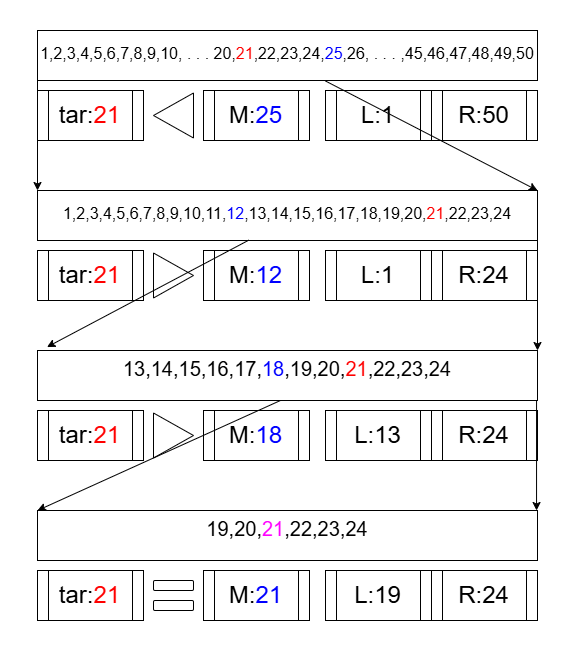

### 二分探索の実装

先程の例をコードで実装すると以下のようになります。  
探索する範囲をleftとrightで定め、探索する値をtargetとします。  
leftとrightの間をmidとし、midとtargetを比較して、leftとrightの範囲を狭めます。

In [ ]:
target = 21
left = 1
right = 50
cnt = 0
while right >= left:
    cnt += 1
    mid = (left + right)//2
    print(f"{mid}と比較します。")
    if mid == target:
        print(f"探索には{cnt}回かかりました。")
        break
    elif mid > target:
        right = mid - 1
    else:
        left = mid + 1


### bisectを用いた二分探索の実装

pythonには`bisect`モジュールがあり、二分探索を簡単に実装することができます。
`bisect`モジュールは、**ソート済みのリスト**に対して、ソート順を崩さずに要素を挿入できる場所を見つけるための二分探索アルゴリズムを提供します。

In [ ]:
import bisect
a = [0,1,3,5,7]
print(bisect.bisect_left(a,4))#配列aの4を挿入できるインデックスを返す


#### Python bisectモジュール 基本操作一覧





| 操作名 | 操作内容 | オーダー |
| :--- | :--- | :--- |
| `bisect.bisect_left(a, x)` | ソート済みリスト`a`に値`x`を挿入できる最も左のインデックスを返す。`x`が`a`内に既に存在する場合、その既存の値の**左側**のインデックスを返す。 | $O(\log n)$ |
| `bisect.bisect_right(a, x)`<br>または `bisect.bisect(a, x)` | ソート済みリスト`a`に値`x`を挿入できる最も右のインデックスを返す。`x`が`a`内に既に存在する場合、その既存の値の**右側**のインデックスを返す。 | $O(\log n)$ |
| bisect.insort_left(a, x) | `bisect_left`で見つけた位置に、実際に値`x`をリスト`a`に挿入する。リストの要素をずらすため、挿入自体の計算量は$O(n)$となる。 | $O(\log n) + O(n) = O(n)$ |
| bisect.insort_right(a, x)<br>または bisect.insort(a, x) | `bisect_right`で見つけた位置に、実際に値`x`をリスト`a`に挿入する。挿入自体の計算量は$O(n)$となる。 | $O(\log n) + O(n) = O(n)$ |

#### bisect_left と bisect_right の違い

In [ ]:
import bisect

#            0   1   2   3   4   5
my_list =   [10, 20, 30, 30, 30, 40]
target = 30

# 30を挿入できる一番「左」のインデックスは 2
left_index = bisect.bisect_left(my_list, target)
print(f"bisect_left(30) -> {left_index}")
# => bisect_left(30) -> 2

# 30を挿入できる一番「右」のインデックスは 5
right_index = bisect.bisect_right(my_list, target)
print(f"bisect_right(30) -> {right_index}")
# => bisect_right(30) -> 5

### pythonのソートアルゴリズムについて

pythonの`sort()`や`sorted()`ではTimsortという高速なアルゴリズムが用いられており、
$O(nlog(n))$で配列をソートすることができます。  
これはなかなか高速ではありますが、
ソート処理を何度も行う場合にはコード全体の計算量が増えるので注意が必要です。  
二分探索のオーダーは$O(log(n))$ですが、
与えられたデータがソートされていない場合には、ソートするためのオーダーに計算量が引っ張られてしまうことに注意してください。

### 問題:アルゴ式

#### 問題：最小の添字 [アルゴ式](https://algo-method.com/tasks/370)

In [ ]:
#解答スペース
# print(kotae[1]) #コメントアウトを外すと解答例が表示


#### 問題：小さい数の個数 [アルゴ式](https://algo-method.com/tasks/382)

In [ ]:
#解答スペース
# print(kotae[2]) #コメントアウトを外すと解答例が表示


#### 問題：和が K 以上のペア [アルゴ式](https://algo-method.com/tasks/381)

In [ ]:
#解答スペース
# print(kotae[3]) #コメントアウトを外すと解答例が表示


#### 問題：何番目の重さ？ [アルゴ式](https://algo-method.com/tasks/399)

In [ ]:
#解答スペース
# print(kotae[4]) #コメントアウトを外すと解答例が表示


### 問題:AtCoder

#### 問題：Min Difference [AtCoder](https://atcoder.jp/contests/abc212/tasks/abc212_c)

In [ ]:
#解答スペース
# print(kotae[5]) #コメントアウトを外すと解答例が表示



#### 問題：Reindeer and Sleigh [AtCoder](https://atcoder.jp/contests/abc334/tasks/abc334_d)

In [ ]:
#解答スペース
print(kotae[6]) #コメントアウトを外すと解答例が表示
